# Desempenho de métodos alternativos de estimativa da ETo com dados NASA/POWER no oeste do Paraná

Notebook de análise do artigo submetido à **Revista Brasileira de Iniciação Científica (RBIC)**.
Pode ser executado no Google Colab ou localmente: todos os dados são baixados da internet
(NASA/POWER, malhas do IBGE e Natural Earth) e todas as figuras do artigo são gravadas na pasta `figuras/`.

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fcoliveira-utfpr/ETo_oeste_pr/blob/main/analise_RBIC.ipynb)
(no Colab: *Ambiente de execução > Executar tudo*)

**Procedimento**
- Séries diárias do NASA/POWER de 1995 a 2025 para dez municípios de clima Cfa do oeste do Paraná.
- Vento a 2 m obtido da velocidade corrigida pelo POWER para 10 m sobre grama (`WSC`) e convertida pela
  FAO-56 (Eq. 47); o `WS2M` nativo é avaliado como sensibilidade.
- ETo pelo PM-FAO56 (referência) e por seis métodos alternativos, calculada com o pacote
  [`agrometeorologiapy`](https://pypi.org/project/agrometeorologiapy/) (albedo 0,23; Δ em Tmed; Rs/Rso ≤ 1;
  Ra astronômica no ponto de cada município).
- Desempenho em mm d⁻¹ (RMSE, MAE, viés, NSE, r, d e c), regional pela média das séries meteorológicas
  independentes, apresentado em mapas de calor (verde mais escuro = melhor desempenho em cada métrica).


In [1]:
# Instalação das dependências (necessária no Colab; localmente apenas confirma as versões)
%pip install -q agrometeorologiapy==0.3.0 geopandas pyarrow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import json
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import stats

import agrometeorologiapy as agm

warnings.filterwarnings("ignore", category=FutureWarning)
print("agrometeorologiapy", agm.__version__)

BASE = Path.cwd()
DIR_RES = BASE / "resultados"
DIR_DADOS = DIR_RES / "dados"
DIR_TAB = DIR_RES / "tabelas"
DIR_FIG = BASE / "figuras"  # figuras do artigo
for p in (DIR_DADOS, DIR_TAB, DIR_FIG):
    p.mkdir(parents=True, exist_ok=True)

FORCAR_DOWNLOAD = False  # True para baixar novamente as séries do NASA/POWER

ANO_INI, ANO_FIM = 1995, 2025

# Estilo das figuras (vírgula decimal)
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "font.size": 10,
    "axes.titlesize": 10,
    "axes.labelsize": 10,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})


def virgula(x, casas=2):
    """Formata número com vírgula decimal (sem "-0,00")."""
    x = round(float(x), casas) + 0.0
    return f"{x:.{casas}f}".replace(".", ",")


def fmt_eixo(casas=0):
    return mticker.FuncFormatter(lambda v, _: virgula(v, casas))

agrometeorologiapy 0.3.0


## 1. Municípios

In [3]:
municipios = pd.DataFrame(
    [
        ("Cascavel", "CAS", -25.0277, -53.3796, 712),
        ("Foz do Iguaçu", "FOZ", -25.4708, -54.4824, 275),
        ("Guaíra", "GUA", -24.1915, -54.2277, 275),
        ("Marechal Cândido Rondon", "MCR", -24.5717, -54.1389, 327),
        ("Matelândia", "MAT", -25.3509, -53.9061, 324),
        ("Medianeira", "MED", -25.2632, -54.0919, 401),
        ("Santa Helena", "SHE", -24.8872, -54.3062, 238),
        ("São Miguel do Iguaçu", "SMI", -25.3882, -54.2619, 299),
        ("São Pedro do Iguaçu", "SPI", -24.9065, -53.8908, 517),
        ("Toledo", "TOL", -24.7048, -53.7780, 524),
    ],
    columns=["Municipio", "Sigla", "Lat", "Lon", "Alt"],
)
municipios

,Municipio,Sigla,Lat,Lon,Alt
0,Cascavel,CAS,-25.0277,-53.3796,712
1,Foz do Iguaçu,FOZ,-25.4708,-54.4824,275
2,Guaíra,GUA,-24.1915,-54.2277,275
3,Marechal Cândido Rondon,MCR,-24.5717,-54.1389,327
4,Matelândia,MAT,-25.3509,-53.9061,324
5,Medianeira,MED,-25.2632,-54.0919,401
6,Santa Helena,SHE,-24.8872,-54.3062,238
7,São Miguel do Iguaçu,SMI,-25.3882,-54.2619,299
8,São Pedro do Iguaçu,SPI,-24.9065,-53.8908,517
9,Toledo,TOL,-24.7048,-53.7780,524


## 2. Download das séries diárias do NASA/POWER

Comunidade AG (radiação já em MJ m⁻² d⁻¹). O parâmetro `WSC` é a velocidade do vento corrigida pelo
próprio POWER para 10 m de altura sobre superfície de grama (`wind-elevation=10`, `wind-surface=airportgrass`),
obtida a partir do vento a 50 m pelo perfil logarítmico com a rugosidade da superfície escolhida.

In [4]:
PARAMS = ["T2M_MAX", "T2M_MIN", "RH2M", "PRECTOTCORR", "ALLSKY_SFC_SW_DWN",
          "TOA_SW_DWN", "WS2M", "WS10M", "WS50M"]
URL = "https://power.larc.nasa.gov/api/temporal/daily/point"


def baixar_power(lat, lon):
    q = {
        "parameters": ",".join(PARAMS),
        "community": "AG",
        "latitude": lat,
        "longitude": lon,
        "start": f"{ANO_INI}0101",
        "end": f"{ANO_FIM}1231",
        "format": "JSON",
        "wind-elevation": 10,
        "wind-surface": "airportgrass",
    }
    r = requests.get(URL, params=q, timeout=300)
    r.raise_for_status()
    js = r.json()
    par = js["properties"]["parameter"]
    df = pd.DataFrame(par)
    df.index = pd.to_datetime(df.index, format="%Y%m%d")
    df.index.name = "Data"
    df = df.replace(js["header"].get("fill_value", -999.0), np.nan)
    meta = {"api": js["header"]["api"], "fontes": js["header"]["sources"],
            "mensagens": js.get("messages", []), "elev_grade_m": js["geometry"]["coordinates"][2]}
    return df, meta


meta_download = {}
arq_meta = DIR_DADOS / "metadados_download.json"
if arq_meta.exists() and not FORCAR_DOWNLOAD:
    meta_download = json.loads(arq_meta.read_text(encoding="utf-8"))

brutos = {}
for _, m in municipios.iterrows():
    arq = DIR_DADOS / f"power_{m.Sigla}.csv"
    if arq.exists() and not FORCAR_DOWNLOAD:
        brutos[m.Municipio] = pd.read_csv(arq, index_col="Data", parse_dates=True)
        continue
    df, meta = baixar_power(m.Lat, m.Lon)
    df.to_csv(arq)
    meta["acesso"] = datetime.now().strftime("%Y-%m-%d %H:%M")
    meta_download[m.Municipio] = meta
    brutos[m.Municipio] = df
    print("baixado:", m.Municipio, df.shape)

arq_meta.write_text(json.dumps(meta_download, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(next(iter(meta_download.values())), ensure_ascii=False, indent=1))

{
 "api": {
  "version": "v2.10.0",
  "name": "POWER Daily API"
 },
 "fontes": [
  "SYN1DEG",
  "SRB",
  "MERRA2",
  "POWER"
 ],
 "mensagens": [
  "Corrected Wind Speed has a custom surface implemented: Airport: flat rough grass (airportgrass)"
 ],
 "elev_grade_m": 612.33,
 "acesso": "2026-10-14 11:35"
}


### Controle de qualidade: falhas, vento nativo e grade da reanálise

In [5]:
falhas = pd.DataFrame({k: v.isna().sum() for k, v in brutos.items()}).T
print("Dias com falha por variável:\n", falhas.loc[:, falhas.sum() > 0] if falhas.values.sum() else "nenhuma")

# Falhas pontuais são preenchidas por interpolação linear (limite de 3 dias)
for k in brutos:
    brutos[k] = brutos[k].interpolate(limit=3, limit_direction="both")

vento = pd.DataFrame({
    k: {"WS2M nativo": v.WS2M.mean(), "WS10M nativo": v.WS10M.mean(),
        "WS50M": v.WS50M.mean(), "WSC 10 m grama": v.WSC.mean()}
    for k, v in brutos.items()}).T
vento["u2 (FAO Eq. 47)"] = agm.vento_2m(vento["WSC 10 m grama"], 10)
vento.round(2)

Dias com falha por variável:
 nenhuma


,WS2M nativo,WS10M nativo,WS50M,WSC 10 m grama,u2 (FAO Eq. 47)
Cascavel,0.09,1.11,2.71,2.13,1.59
Foz do Iguaçu,0.87,1.79,3.23,2.54,1.90
Guaíra,0.62,1.80,3.43,2.69,2.01
Marechal Cândido Rondon,1.58,2.43,3.62,2.84,2.13
Matelândia,0.18,1.17,2.70,2.12,1.59
Medianeira,0.87,1.79,3.23,2.54,1.90
Santa Helena,2.33,3.10,4.11,3.23,2.42
São Miguel do Iguaçu,0.87,1.79,3.23,2.54,1.90
São Pedro do Iguaçu,0.74,2.10,3.88,3.05,2.28
Toledo,0.99,2.20,4.03,3.16,2.37


In [6]:
# Identificação de séries de entrada idênticas (mesma célula da grade)
def grupos_identicos(cols):
    assin = {k: pd.util.hash_pandas_object(v[cols].round(4), index=False).sum() for k, v in brutos.items()}
    grupos = {}
    for k, h in assin.items():
        grupos.setdefault(h, []).append(k)
    return list(grupos.values())


COLS_MET = ["T2M_MAX", "T2M_MIN", "RH2M", "WSC", "ALLSKY_SFC_SW_DWN"]
grupos_met = grupos_identicos(COLS_MET)
grupos_rad = grupos_identicos(["ALLSKY_SFC_SW_DWN"])
print("Séries meteorológicas independentes:", len(grupos_met))
for g in grupos_met:
    print("  ", g)
print("Séries de radiação solar independentes:", len(grupos_rad))
for g in grupos_rad:
    print("  ", g)

# Representante de cada grupo (primeiro em ordem alfabética) -> usado nas médias regionais
independentes = [sorted(g)[0] for g in grupos_met]
grupo_de = {k: g for g in grupos_met for k in g}

Séries meteorológicas independentes: 8
   ['Cascavel']
   ['Foz do Iguaçu', 'Medianeira', 'São Miguel do Iguaçu']
   ['Guaíra']
   ['Marechal Cândido Rondon']
   ['Matelândia']
   ['Santa Helena']
   ['São Pedro do Iguaçu']
   ['Toledo']
Séries de radiação solar independentes: 4
   ['Cascavel', 'Matelândia']
   ['Foz do Iguaçu', 'Medianeira', 'São Miguel do Iguaçu']
   ['Guaíra', 'Marechal Cândido Rondon', 'Santa Helena']
   ['São Pedro do Iguaçu', 'Toledo']


## 3. Cálculo da ETo com o `agrometeorologiapy`

In [7]:
# Tabela de Camargo (1971) apud Pereira et al. (1997): até 23,5 °C -> 0,0100; 24 -> 0,0105; 25 -> 0,0110;
# 26 -> 0,0115; 27 -> 0,0120; 28 -> 0,0130. Usa-se o valor tabelado mais próximo.
F_CAMARGO = [(23.75, 0.0100), (24.5, 0.0105), (25.5, 0.0110), (26.5, 0.0115), (27.5, 0.0120), (99, 0.0130)]


def fator_camargo(tmed_anual):
    """Fator F de Camargo (1971) em função da temperatura média anual (Pereira et al., 1997)."""
    return next(f for lim, f in F_CAMARGO if tmed_anual <= lim)


def eto_ghs(Ra, Tmax, Tmin, Tmed):
    """Hargreaves-Samani calibrado para o oeste do Paraná (Giovanella et al., 2023)."""
    return 0.0009 * (Tmed + 100) * (Tmax - Tmin) ** 0.49 * 0.408 * Ra


def eto_camargo(Ra, Tmed, F):
    """Camargo (1971), escala diária."""
    return F * 0.408 * Ra * Tmed


def eto_turc(Rs, Tmed, UR):
    """Turc (1961), versão no SI (Rs em MJ m-2 d-1), com correção para UR < 50 %."""
    base = 0.31 * Tmed / (Tmed + 15) * (Rs + 2.09)
    return np.where(UR < 50, base * (1 + (50 - UR) / 70), base)


def eto_makkink(Rs, Delta, gamma):
    """Makkink (1957): 0,61 Δ/(Δ+γ) Rs/λ − 0,12."""
    return 0.61 * Delta / (Delta + gamma) * Rs / 2.45 - 0.12


def processar(m, bruto, u2_col="WSC"):
    d = pd.DataFrame(index=bruto.index)
    d["Tmax"], d["Tmin"] = bruto.T2M_MAX, bruto.T2M_MIN
    d["Tmed"] = agm.temp_media_extremos(d.Tmax, d.Tmin)
    d["UR"] = bruto.RH2M
    d["P"] = bruto.PRECTOTCORR
    d["Rs"] = bruto.ALLSKY_SFC_SW_DWN
    d["u2"] = agm.vento_2m(bruto[u2_col], 10) if u2_col != "WS2M" else bruto.WS2M

    # Radiação extraterrestre (equações astronômicas, coordenada do município)
    nda = d.index.dayofyear.to_numpy()
    dec = agm.declinacao_solar(nda)
    hn = agm.angulo_horario_nascer(m.Lat, dec)
    d["Ra"] = agm.irradiancia_extraterrestre(m.Lat, dec, hn, agm.fator_correcao_distancia(nda))
    d["Ra_POWER"] = bruto.TOA_SW_DWN
    d["Rso"] = (0.75 + 2e-5 * m.Alt) * d.Ra

    # Umidade e constantes
    d["es"] = (agm.es_tetens(d.Tmax) + agm.es_tetens(d.Tmin)) / 2
    d["ea"] = agm.ea_umidade(d.es, d.UR)
    d["Delta"] = agm.declive_pressao_vapor(d.Tmed)
    d["gamma"] = agm.constante_psicrometrica(agm.patm_altitude(m.Alt))

    # Saldo de radiação (albedo 0,23; Rs/Rso <= 1)
    rs_lim = np.minimum(d.Rs, d.Rso)
    d["BOC"] = agm.boc_saldo(d.Rs, r=0.23)
    d["BOL"] = agm.bol_saldo(d.Tmax, d.Tmin, d.ea, rs_lim, d.Rso)
    d["Rn"] = agm.saldo_radiacao(d.BOC, d.BOL)

    # ETo de referência e termos do PM-FAO56
    d["PM"] = agm.eto_penman_monteith_fao56(d.Rn, 0, d.Tmed, d.u2, d.es, d.ea, d.Delta, d.gamma)
    den = d.Delta + d.gamma * (1 + 0.34 * d.u2)
    d["PM_rad"] = 0.408 * d.Delta * d.Rn / den
    d["PM_aero"] = d.PM - d.PM_rad

    # Métodos alternativos
    F = fator_camargo(d.Tmed.mean())
    d["HS"] = agm.etp_hargreaves_samani(d.Ra, d.Tmax, d.Tmin, d.Tmed)
    d["GHS"] = eto_ghs(d.Ra, d.Tmax, d.Tmin, d.Tmed)
    d["Cam"] = eto_camargo(d.Ra, d.Tmed, F)
    d["Tur"] = eto_turc(d.Rs, d.Tmed, d.UR)
    d["PT"] = agm.etp_priestley_taylor(d.Rn, 0, d.Delta, d.gamma)
    d["Mak"] = eto_makkink(d.Rs, d.Delta, d.gamma)

    d["Municipio"] = m.Municipio
    d.attrs["F_camargo"] = F
    return d


serie = {m.Municipio: processar(m, brutos[m.Municipio]) for _, m in municipios.iterrows()}
df = pd.concat(serie.values())
df.to_csv(DIR_DADOS / "eto_diaria_municipios.csv.gz", float_format="%.4f", compression="gzip")

METODOS = ["Tur", "PT", "Mak", "HS", "GHS", "Cam"]
NOMES = {"HS": "Hargreaves-Samani", "GHS": "GHS", "Cam": "Camargo", "Tur": "Turc",
         "PT": "Priestley-Taylor", "Mak": "Makkink"}

print("Fator F de Camargo:", {k: v.attrs["F_camargo"] for k, v in serie.items()})
print("Dias com Rs > Rso:", int((df.Rs > df.Rso).sum()), f"({(df.Rs > df.Rso).mean():.2%})")
print("Dias com ETo negativa:", (df[["PM"] + METODOS] < 0).sum().to_dict())
print("Ra astronômica - Ra POWER (média, MJ m-2 d-1):", round((df.Ra - df.Ra_POWER).mean(), 3),
      "| r =", round(df[["Ra", "Ra_POWER"]].corr().iloc[0, 1], 4))
print("Dias por município:", len(df) // len(serie))

Fator F de Camargo: {'Cascavel': 0.01, 'Foz do Iguaçu': 0.01, 'Guaíra': 0.01, 'Marechal Cândido Rondon': 0.01, 'Matelândia': 0.01, 'Medianeira': 0.01, 'Santa Helena': 0.01, 'São Miguel do Iguaçu': 0.01, 'São Pedro do Iguaçu': 0.01, 'Toledo': 0.01}
Dias com Rs > Rso: 875 (0.77%)
Dias com ETo negativa: {'PM': 0, 'Tur': 0, 'PT': 0, 'Mak': 3, 'HS': 0, 'GHS': 0, 'Cam': 0}
Ra astronômica - Ra POWER (média, MJ m-2 d-1): 0.301 | r = 0.9995
Dias por município: 11323


## 4. Caracterização meteorológica

In [8]:
VARS_CLIMA = ["Tmin", "Tmax", "Tmed", "UR", "u2", "Rs", "Ra", "PM"]
clima = df.groupby("Municipio")[VARS_CLIMA].agg(["mean", "std"])
chuva_anual = df.groupby(["Municipio", df.index.year])["P"].sum().unstack(0)
clima[("P", "mean")] = chuva_anual.mean()
clima[("P", "std")] = chuva_anual.std()
clima = clima.loc[municipios.Municipio]
clima.columns = [f"{v}_{s}" for v, s in clima.columns]
clima.insert(0, "Alt", municipios.set_index("Municipio").Alt)
clima["u2_WS2M_nativo"] = vento["WS2M nativo"]
clima.to_csv(DIR_TAB / "caracterizacao_meteorologica.csv", float_format="%.3f")
clima.round(2)

,Alt,Tmin_mean,Tmin_std,Tmax_mean,Tmax_std,Tmed_mean,Tmed_std,UR_mean,UR_std,u2_mean,u2_std,Rs_mean,Rs_std,Ra_mean,Ra_std,PM_mean,PM_std,P_mean,P_std,u2_WS2M_nativo
Municipio,,,,,,,,,,,,,,,,,,,,
Cascavel,712,15.42,4.58,25.69,4.39,20.55,4.20,79.63,10.35,1.59,0.41,17.45,7.42,33.15,7.85,3.30,1.49,1665.91,316.71,0.09
Foz do Iguaçu,275,18.18,5.17,27.63,5.20,22.91,4.93,74.87,11.74,1.90,0.52,17.55,7.64,33.04,7.97,3.70,1.74,1629.85,316.87,0.87
Guaíra,275,18.04,4.72,28.99,4.94,23.52,4.54,75.07,10.18,2.01,0.52,17.69,7.35,33.34,7.64,3.82,1.66,1495.57,232.84,0.62
Marechal Cândido Rondon,327,19.26,4.71,27.78,4.90,23.52,4.59,73.03,11.21,2.13,0.58,17.69,7.35,33.25,7.74,3.88,1.69,1551.15,246.56,1.58
Matelândia,324,16.44,4.85,27.10,4.97,21.77,4.63,77.10,11.34,1.59,0.40,17.45,7.42,33.07,7.94,3.45,1.60,1678.39,318.63,0.18
Medianeira,401,18.18,5.17,27.63,5.20,22.91,4.93,74.87,11.74,1.90,0.52,17.55,7.64,33.09,7.91,3.71,1.74,1629.85,316.87,0.87
Santa Helena,238,19.68,4.98,27.38,4.95,23.53,4.79,71.88,11.19,2.42,0.72,17.69,7.35,33.18,7.82,3.97,1.75,1598.69,275.72,2.33
São Miguel do Iguaçu,299,18.18,5.17,27.63,5.20,22.91,4.93,74.87,11.74,1.90,0.52,17.55,7.64,33.06,7.95,3.71,1.74,1629.85,316.87,0.87
São Pedro do Iguaçu,517,15.63,4.82,27.00,4.79,21.32,4.50,77.62,10.47,2.28,0.62,17.78,7.18,33.17,7.82,3.58,1.60,1615.18,275.94,0.74


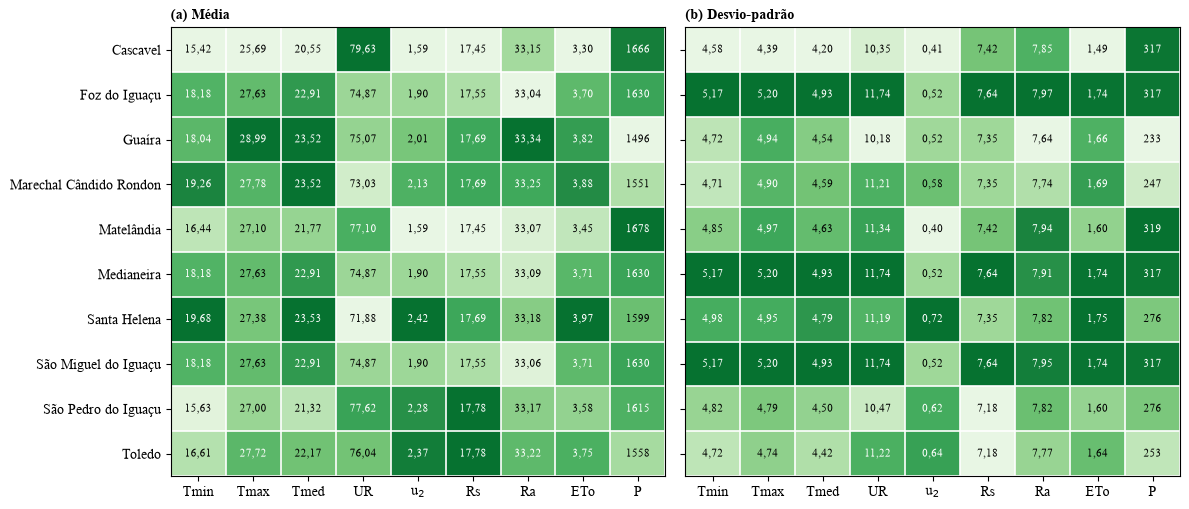

In [9]:
rotulos_clima = {"Tmin": "Tmin", "Tmax": "Tmax", "Tmed": "Tmed", "UR": "UR", "u2": "u$_2$",
                 "Rs": "Rs", "Ra": "Ra", "PM": "ETo", "P": "P"}
vars_fig = ["Tmin", "Tmax", "Tmed", "UR", "u2", "Rs", "Ra", "PM", "P"]

fig, axs = plt.subplots(1, 2, figsize=(12, 5.2), sharey=True)
for ax, est, tit in zip(axs, ["mean", "std"], ["(a) Média", "(b) Desvio-padrão"]):
    mat = clima[[f"{v}_{est}" for v in vars_fig]].to_numpy()
    rng = np.ptp(mat, axis=0)
    norm = np.where(rng > 0, (mat - mat.min(0)) / np.where(rng > 0, rng, 1), 0.5)
    ax.imshow(plt.cm.Greens(0.1 + 0.75 * norm), aspect="auto")
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            casas = 0 if vars_fig[j] == "P" else 2
            ax.text(j, i, virgula(mat[i, j], casas), ha="center", va="center", fontsize=8,
                    color="white" if norm[i, j] > 0.6 else "black")
    ax.set_xticks(range(len(vars_fig)), [rotulos_clima[v] for v in vars_fig])
    ax.set_yticks(range(len(clima)), clima.index)
    ax.set_title(tit, loc="left", fontweight="bold")
    ax.set_xticks(np.arange(-0.5, len(vars_fig)), minor=True)
    ax.set_yticks(np.arange(-0.5, len(clima)), minor=True)
    ax.grid(which="minor", color="white", lw=1.2)
    ax.tick_params(which="minor", length=0)
plt.tight_layout()
plt.savefig(DIR_FIG / "fig_climatologia.png")
plt.show()

### Mapa da área de estudo com as grades do NASA/POWER

Polígonos selecionados: 10


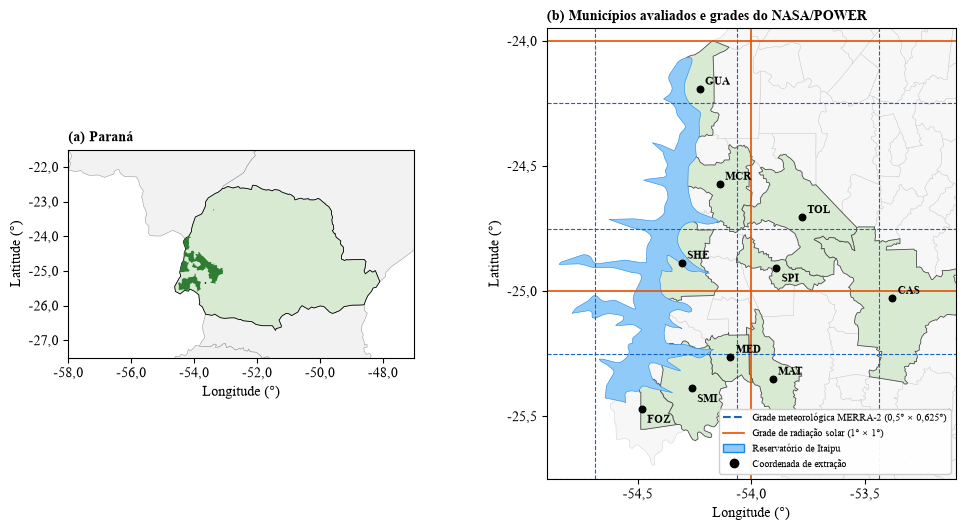

In [10]:
import geopandas as gpd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

GEO = {
    "pr_municipios.geojson": "https://servicodados.ibge.gov.br/api/v3/malhas/estados/41?formato=application/vnd.geo+json&intrarregiao=municipio&qualidade=intermediaria",
    "uf.geojson": "https://servicodados.ibge.gov.br/api/v3/malhas/paises/BR?formato=application/vnd.geo+json&intrarregiao=UF&qualidade=minima",
    "ne_lakes.zip": "https://naciscdn.org/naturalearth/10m/physical/ne_10m_lakes.zip",
}
for nome, url in GEO.items():
    if not (DIR_DADOS / nome).exists():
        (DIR_DADOS / nome).write_bytes(requests.get(url, timeout=300).content)

pr_mun = gpd.read_file(DIR_DADOS / "pr_municipios.geojson")
uf = gpd.read_file(DIR_DADOS / "uf.geojson")
itaipu = gpd.read_file(f"zip://{DIR_DADOS / 'ne_lakes.zip'}").query("name == 'Represa Itaipu'")
pts = gpd.GeoDataFrame(municipios, geometry=gpd.points_from_xy(municipios.Lon, municipios.Lat), crs=pr_mun.crs)
sel = gpd.sjoin(pr_mun, pts, predicate="contains")
print("Polígonos selecionados:", len(sel))

fig, (ax0, ax) = plt.subplots(1, 2, figsize=(11, 5.4), gridspec_kw={"width_ratios": [1, 1.9]})
uf.plot(ax=ax0, color="#f2f2f2", edgecolor="#9a9a9a", lw=0.4)
uf[uf.codarea.astype(str) == "41"].plot(ax=ax0, color="#d9ead3", edgecolor="black", lw=0.6)
sel.dissolve().plot(ax=ax0, color="#2e7d32")
ax0.set_xlim(-58, -47); ax0.set_ylim(-27.5, -21.5)
ax0.set_title("(a) Paraná", loc="left", fontweight="bold")

pr_mun.plot(ax=ax, color="#f7f7f7", edgecolor="#c8c8c8", lw=0.3)
sel.plot(ax=ax, color="#d9ead3", edgecolor="#4d4d4d", lw=0.6)
itaipu.plot(ax=ax, color="#90caf9", edgecolor="#1e88e5", lw=0.4)
xmin, xmax, ymin, ymax = -54.9, -53.1, -25.75, -23.95
# Grade MERRA-2 (0,5° x 0,625°, centros em múltiplos de 0,5° e 0,625°) e grade de radiação (1° x 1°)
for y in np.arange(-90.25, 90, 0.5):
    if ymin <= y <= ymax:
        ax.axhline(y, color="#1565c0", lw=0.8, ls="--")
for x in np.arange(-180 - 0.3125, 180, 0.625):
    if xmin <= x <= xmax:
        ax.axvline(x, color="#1565c0", lw=0.8, ls="--")
for y in np.arange(-90, 90, 1.0):
    if ymin <= y <= ymax:
        ax.axhline(y, color="#e65100", lw=1.2)
for x in np.arange(-180, 180, 1.0):
    if xmin <= x <= xmax:
        ax.axvline(x, color="#e65100", lw=1.2)
ax.scatter(municipios.Lon, municipios.Lat, s=22, color="black", zorder=5)
desloc = {"FOZ": (4, -10), "SMI": (4, -10), "MED": (4, 3), "MAT": (4, 3), "SHE": (4, 3),
          "MCR": (4, 3), "GUA": (4, 3), "TOL": (4, 3), "SPI": (4, -10), "CAS": (4, 3)}
for _, m in municipios.iterrows():
    ax.annotate(m.Sigla, (m.Lon, m.Lat), xytext=desloc[m.Sigla], textcoords="offset points",
                fontsize=8, fontweight="bold")
ax.set_xlim(xmin, xmax); ax.set_ylim(ymin, ymax)
ax.set_title("(b) Municípios avaliados e grades do NASA/POWER", loc="left", fontweight="bold")
ax.legend(handles=[Line2D([], [], color="#1565c0", ls="--", label="Grade meteorológica MERRA-2 (0,5° × 0,625°)"),
                   Line2D([], [], color="#e65100", lw=1.2, label="Grade de radiação solar (1° × 1°)"),
                   Patch(facecolor="#90caf9", edgecolor="#1e88e5", label="Reservatório de Itaipu"),
                   Line2D([], [], marker="o", color="black", ls="", label="Coordenada de extração")],
          loc="lower right", fontsize=7.5, framealpha=0.95)
for a in (ax0, ax):
    a.xaxis.set_major_formatter(fmt_eixo(1)); a.yaxis.set_major_formatter(fmt_eixo(1))
    if a is ax:
        a.xaxis.set_major_locator(mticker.MultipleLocator(0.5)); a.yaxis.set_major_locator(mticker.MultipleLocator(0.5))
    a.set_xlabel("Longitude (°)"); a.set_ylabel("Latitude (°)")
plt.tight_layout()
plt.savefig(DIR_FIG / "fig_mapa.png")
plt.show()

## 5. Métricas de desempenho (mm d⁻¹)

In [11]:
def classe_c(c):
    """Classes de Camargo e Sentelhas (1997), aplicadas ao valor de c arredondado a duas casas."""
    c = round(c, 2)
    for lim, nome in [(0.85, "Ótimo"), (0.76, "Muito bom"), (0.66, "Bom"), (0.61, "Mediano"),
                      (0.51, "Sofrível"), (0.41, "Mau")]:
        if c >= lim and (lim != 0.85 or c > lim):
            return nome
    return "Péssimo"


def classe_nse(n):
    return "Adequado" if n > 0.75 else ("Satisfatório" if n > 0.36 else "Não satisfatório")


def metricas(o, e):
    o, e = np.asarray(o, float), np.asarray(e, float)
    ok = np.isfinite(o) & np.isfinite(e)
    o, e = o[ok], e[ok]
    err = e - o
    om = o.mean()
    r = stats.pearsonr(o, e)[0]
    d = 1 - np.sum(err ** 2) / np.sum((np.abs(e - om) + np.abs(o - om)) ** 2)
    b, a = np.polyfit(o, e, 1)  # E = a + b·O
    return {
        "n": len(o), "RMSE": np.sqrt(np.mean(err ** 2)), "MAE": np.mean(np.abs(err)),
        "Vies": err.mean(), "Vies_pct": 100 * err.mean() / om,
        "NSE": 1 - np.sum(err ** 2) / np.sum((o - om) ** 2),
        "r": r, "d": d, "c": r * d, "a": a, "b": b, "R2": r ** 2,
    }


linhas = []
for mun, s in serie.items():
    for met in METODOS:
        linhas.append({"Municipio": mun, "Metodo": met, **metricas(s.PM, s[met])})
desemp = pd.DataFrame(linhas)
desemp["Independente"] = desemp.Municipio.isin(independentes)
desemp["Classe_c"] = desemp.c.apply(classe_c)
desemp["Classe_NSE"] = desemp.NSE.apply(classe_nse)
desemp.to_csv(DIR_TAB / "desempenho_por_municipio.csv", index=False, float_format="%.4f")

# Desempenho regional: média das séries meteorológicas independentes
cols_m = ["RMSE", "MAE", "Vies", "Vies_pct", "NSE", "r", "d", "c", "a", "b"]
regional = (desemp[desemp.Independente].groupby("Metodo")[cols_m].mean()
            .loc[METODOS].sort_values("c", ascending=False))
regional["Classe_c"] = regional.c.apply(classe_c)
regional["Classe_NSE"] = regional.NSE.apply(classe_nse)
# Amplitude entre as séries independentes
amp = desemp[desemp.Independente].groupby("Metodo")[["c", "NSE", "RMSE"]].agg(["min", "max"])
regional.to_csv(DIR_TAB / "desempenho_regional.csv", float_format="%.4f")
amp.to_csv(DIR_TAB / "desempenho_regional_amplitude.csv", float_format="%.4f")
regional.round(3)

,RMSE,MAE,Vies,Vies_pct,NSE,r,d,c,a,b,Classe_c,Classe_NSE
Metodo,,,,,,,,,,,,
Tur,0.487,0.373,-0.001,0.163,0.912,0.959,0.976,0.936,0.385,0.897,Ótimo,Adequado
PT,0.655,0.513,0.266,7.484,0.837,0.953,0.964,0.918,-0.018,1.079,Ótimo,Adequado
Mak,0.823,0.663,-0.617,-16.585,0.747,0.948,0.929,0.881,0.043,0.822,Ótimo,Satisfatório
HS,0.863,0.647,0.280,8.024,0.722,0.895,0.919,0.822,1.170,0.761,Muito bom,Satisfatório
GHS,1.228,1.034,0.875,24.351,0.409,0.884,0.849,0.750,1.851,0.738,Bom,Satisfatório
Cam,1.188,0.989,-0.543,-14.697,0.477,0.768,0.819,0.629,1.076,0.560,Mediano,Satisfatório


In [12]:
# Desempenho com os dados agregados de todas as séries independentes (verificação)
pool = df[df.Municipio.isin(independentes)]
pd.DataFrame({m: metricas(pool.PM, pool[m]) for m in METODOS}).T[["RMSE", "MAE", "Vies", "NSE", "r", "d", "c"]].round(3)

,RMSE,MAE,Vies,NSE,r,d,c
Tur,0.489,0.373,-0.001,0.913,0.956,0.976,0.933
PT,0.657,0.513,0.266,0.843,0.948,0.965,0.915
Mak,0.837,0.663,-0.617,0.746,0.944,0.928,0.876
HS,0.864,0.647,0.280,0.729,0.871,0.918,0.800
GHS,1.245,1.034,0.875,0.437,0.846,0.844,0.714
Cam,1.190,0.989,-0.543,0.486,0.771,0.822,0.634


### Mapas de calor do desempenho

A cor é escalonada **dentro de cada métrica**, de modo que o verde mais escuro indica o melhor desempenho
naquela métrica: maior valor para NSE, r, d e c; menor valor para RMSE e MAE; menor valor absoluto para o
viés e para o coeficiente linear (a); coeficiente angular (b) mais próximo de 1.

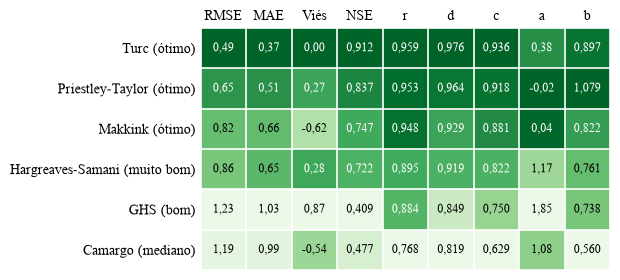

In [13]:
SENTIDO = {"RMSE": "menor", "MAE": "menor", "Vies": "abs", "NSE": "maior", "r": "maior", "d": "maior",
           "c": "maior", "a": "abs", "b": "um"}
ROTULO_M = {"RMSE": "RMSE", "MAE": "MAE", "Vies": "Viés", "NSE": "NSE", "r": "r", "d": "d", "c": "c",
            "a": "a", "b": "b"}
ABREV = {"HS": "HS", "GHS": "GHS", "Cam": "Cam", "Tur": "Tur", "PT": "PT", "Mak": "Mak"}


def escore(v, sentido):
    """Escore de 0 (pior) a 1 (melhor) dentro de uma métrica."""
    v = np.asarray(v, float)
    if sentido == "abs":
        v = -np.abs(v)
    elif sentido == "menor":
        v = -v
    elif sentido == "um":
        v = -np.abs(v - 1)
    amp = np.ptp(v)
    return np.full_like(v, 0.5) if amp == 0 else (v - v.min()) / amp


def celula_verde(ax, i, j, valor, s, casas, fs):
    ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, color=plt.cm.Greens(0.08 + 0.82 * s), lw=0))
    ax.text(j, i, virgula(valor, casas), ha="center", va="center", fontsize=fs,
            color="white" if s > 0.6 else "black")


def grade(ax, nl, nc):
    ax.set_xlim(-0.5, nc - 0.5); ax.set_ylim(nl - 0.5, -0.5)
    for k in range(nl + 1):
        ax.axhline(k - 0.5, color="white", lw=1.2)
    for k in range(nc + 1):
        ax.axvline(k - 0.5, color="white", lw=1.2)
    ax.tick_params(length=0)
    for s_ in ax.spines.values():
        s_.set_visible(False)


# (a) Desempenho regional: métodos x métricas, cor por coluna (métrica)
mets = ["RMSE", "MAE", "Vies", "NSE", "r", "d", "c", "a", "b"]
casas = {"RMSE": 2, "MAE": 2, "Vies": 2, "NSE": 3, "r": 3, "d": 3, "c": 3, "a": 2, "b": 3}
fig, ax = plt.subplots(figsize=(6.3, 2.9))
for j, m in enumerate(mets):
    s = escore(regional[m], SENTIDO[m])
    for i, (met, v) in enumerate(regional[m].items()):
        celula_verde(ax, i, j, v, s[i], casas[m], 8.5)
grade(ax, len(regional), len(mets))
ax.set_xticks(range(len(mets)), [ROTULO_M[m] for m in mets])
ax.xaxis.tick_top()
ax.set_yticks(range(len(regional)), [f"{NOMES[m]} ({regional.loc[m, 'Classe_c'].lower()})" for m in regional.index])
plt.tight_layout()
plt.savefig(DIR_FIG / "fig_desempenho_regional.png")
plt.show()

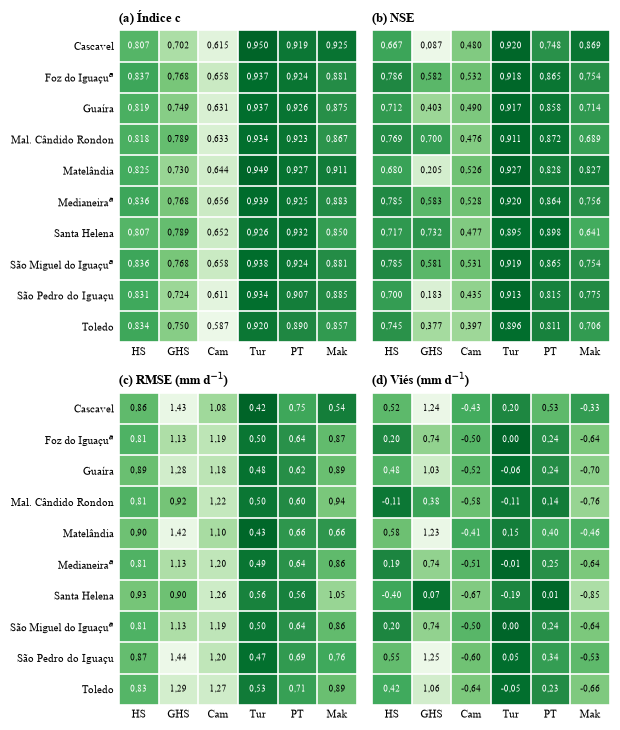

In [14]:
# (b) Desempenho por município: um painel por métrica, cor escalonada dentro de cada painel
paineis = [("c", "(a) Índice c", 3), ("NSE", "(b) NSE", 3), ("RMSE", "(c) RMSE (mm d$^{-1}$)", 2),
           ("Vies", "(d) Viés (mm d$^{-1}$)", 2)]
ordem = ["HS", "GHS", "Cam", "Tur", "PT", "Mak"]
nomes_mun = [m.replace("Marechal", "Mal.") + ("$^{a}$" if len(grupo_de[m]) > 1 else "") for m in municipios.Municipio]
fig, axs = plt.subplots(2, 2, figsize=(6.3, 7.4))
for ax, (col, tit, cs) in zip(axs.flat, paineis):
    piv = desemp.pivot(index="Municipio", columns="Metodo", values=col).loc[municipios.Municipio, ordem]
    s = escore(piv.to_numpy().ravel(), SENTIDO[col]).reshape(piv.shape)
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            celula_verde(ax, i, j, piv.iat[i, j], s[i, j], cs, 6.8)
    grade(ax, *piv.shape)
    ax.set_xticks(range(len(ordem)), [ABREV[m] for m in ordem], fontsize=8)
    ax.set_yticks(range(len(nomes_mun)), nomes_mun if ax in axs[:, 0] else [], fontsize=8)
    ax.set_title(tit, loc="left", fontweight="bold", fontsize=9)
plt.tight_layout()
plt.savefig(DIR_FIG / "fig_desempenho_municipios.png")
plt.show()

## 6. Dispersões (ETo alternativa × PM-FAO56)

In [15]:
CORES = {"HS": "#c62828", "GHS": "#ad1457", "Cam": "#6a1b9a", "Tur": "#1565c0", "PT": "#00838f", "Mak": "#2e7d32"}
ORDEM_FIG = ["HS", "GHS", "Cam", "Tur", "PT", "Mak"]


def painel(ax, s, met, lim=9):
    o, e = s.PM.to_numpy(), s[met].to_numpy()
    k = metricas(o, e)
    ax.scatter(o, e, s=1.5, alpha=0.18, color=CORES[met], rasterized=True, lw=0)
    ax.plot([0, lim], [0, lim], "k--", lw=0.8)
    xx = np.array([0, lim])
    ax.plot(xx, k["a"] + k["b"] * xx, color="black", lw=1.1)
    sinal = "+" if k["a"] >= 0 else "−"
    ax.text(0.04, 0.96, f"{NOMES[met]}\ny = {virgula(k['b'])}x {sinal} {virgula(abs(k['a']))}\n"
            f"R² = {virgula(k['R2'])}  c = {virgula(k['c'])}",
            transform=ax.transAxes, va="top", fontsize=7.5)
    ax.set_xlim(0, lim); ax.set_ylim(0, lim); ax.set_aspect("equal")
    ax.xaxis.set_major_locator(mticker.MultipleLocator(2)); ax.yaxis.set_major_locator(mticker.MultipleLocator(2))


def fig_dispersao(muns, arquivo, rotulos=None):
    fig, axs = plt.subplots(len(muns), 6, figsize=(13, 2.35 * len(muns) + 0.4), sharex=True, sharey=True)
    axs = np.atleast_2d(axs)
    for i, mun in enumerate(muns):
        for j, met in enumerate(ORDEM_FIG):
            painel(axs[i, j], serie[mun], met)
        rot = rotulos[i] if rotulos else mun
        axs[i, 0].set_ylabel(f"{rot}\nETo método (mm d$^{{-1}}$)")
    for ax in axs[-1]:
        ax.set_xlabel("ETo PM-FAO56 (mm d$^{-1}$)")
    plt.tight_layout(w_pad=0.4, h_pad=0.6)
    plt.savefig(DIR_FIG / arquivo)
    plt.show()

## 7. Elementos meteorológicos associados à ETo

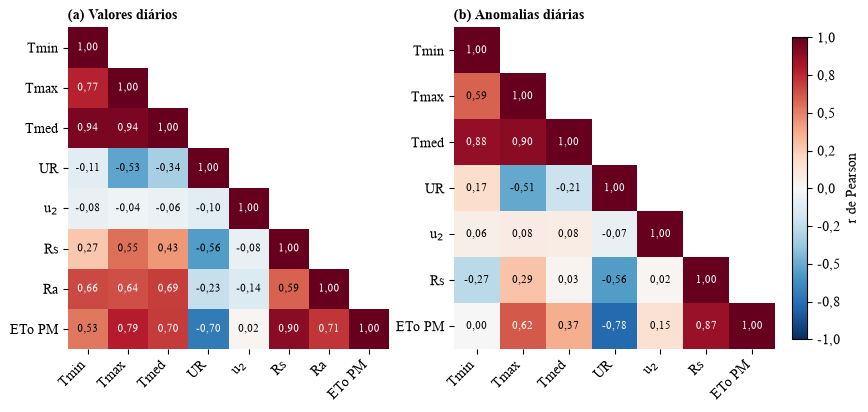

,Tmin,Tmax,Tmed,UR,u2,Rs,Ra,PM
Tmin,1.00,0.77,0.94,-0.11,-0.08,0.27,0.66,0.53
Tmax,0.77,1.00,0.94,-0.53,-0.04,0.55,0.64,0.79
Tmed,0.94,0.94,1.00,-0.34,-0.06,0.43,0.69,0.70
UR,-0.11,-0.53,-0.34,1.00,-0.10,-0.56,-0.23,-0.70
u2,-0.08,-0.04,-0.06,-0.10,1.00,-0.08,-0.14,0.02
Rs,0.27,0.55,0.43,-0.56,-0.08,1.00,0.59,0.90
Ra,0.66,0.64,0.69,-0.23,-0.14,0.59,1.00,0.71
PM,0.53,0.79,0.70,-0.70,0.02,0.90,0.71,1.00


In [16]:
VARS_COR = ["Tmin", "Tmax", "Tmed", "UR", "u2", "Rs", "Ra", "PM"]
ROT_COR = ["Tmin", "Tmax", "Tmed", "UR", "u$_2$", "Rs", "Ra", "ETo PM"]
cor = pool[VARS_COR].corr()

# Correlação das anomalias diárias (remove o ciclo sazonal médio de cada série)
anom = pool.groupby(["Municipio", pool.index.dayofyear])[VARS_COR].transform(lambda x: x - x.mean())
cor_anom = anom[[v for v in VARS_COR if v != "Ra"]].corr()
cor.to_csv(DIR_TAB / "correlacao_pearson.csv", float_format="%.3f")
cor_anom.to_csv(DIR_TAB / "correlacao_pearson_anomalias.csv", float_format="%.3f")


def heat_cor(ax, c, rot, titulo):
    mask = np.triu(np.ones_like(c, bool), k=1)
    m = np.ma.array(c.to_numpy(), mask=mask)
    im = ax.imshow(m, cmap="RdBu_r", vmin=-1, vmax=1)
    for i in range(len(c)):
        for j in range(i + 1):
            v = c.iloc[i, j]
            ax.text(j, i, virgula(v), ha="center", va="center", fontsize=8,
                    color="white" if abs(v) > 0.6 else "black")
    ax.set_xticks(range(len(c)), rot, rotation=45, ha="right")
    ax.set_yticks(range(len(c)), rot)
    ax.set_title(titulo, loc="left", fontweight="bold")
    for s in ax.spines.values():
        s.set_visible(False)
    return im


fig, axs = plt.subplots(1, 2, figsize=(11, 4.9))
heat_cor(axs[0], cor, ROT_COR, "(a) Valores diários")
im = heat_cor(axs[1], cor_anom, [r for v, r in zip(VARS_COR, ROT_COR) if v != "Ra"], "(b) Anomalias diárias")
cb = fig.colorbar(im, ax=axs, shrink=0.8, pad=0.02)
cb.set_label("r de Pearson"); cb.ax.yaxis.set_major_formatter(fmt_eixo(1))
plt.savefig(DIR_FIG / "fig_correlacao.png")
plt.show()
cor.round(2)

In [17]:
cor_anom.round(2)

,Tmin,Tmax,Tmed,UR,u2,Rs,PM
Tmin,1.00,0.59,0.88,0.17,0.06,-0.27,0.00
Tmax,0.59,1.00,0.90,-0.51,0.08,0.29,0.62
Tmed,0.88,0.90,1.00,-0.21,0.08,0.03,0.37
UR,0.17,-0.51,-0.21,1.00,-0.07,-0.56,-0.78
u2,0.06,0.08,0.08,-0.07,1.00,0.02,0.15
Rs,-0.27,0.29,0.03,-0.56,0.02,1.00,0.87
PM,0.00,0.62,0.37,-0.78,0.15,0.87,1.00


## 8. Vento × desempenho dos métodos sem termo aerodinâmico

In [18]:
assoc = []
for mun in independentes:
    s = serie[mun]
    lin = {"Municipio": mun, "u2": s.u2.mean(), "frac_aero": s.PM_aero.sum() / s.PM.sum(),
           "DPV": (s.es - s.ea).mean()}
    for met in METODOS:
        k = desemp[(desemp.Municipio == mun) & (desemp.Metodo == met)].iloc[0]
        lin[f"c_{met}"], lin[f"NSE_{met}"], lin[f"Vies_{met}"] = k.c, k.NSE, k.Vies
    assoc.append(lin)
assoc = pd.DataFrame(assoc).set_index("Municipio").sort_values("u2")
assoc.to_csv(DIR_TAB / "vento_desempenho_series_independentes.csv", float_format="%.4f")


def correl(x, y):
    r, pr = stats.pearsonr(x, y)
    rs, ps = stats.spearmanr(x, y)
    return {"n": len(x), "r": r, "p_r": pr, "rho": rs, "p_rho": ps}


testes = []
mais_ventosos = assoc.u2.nlargest(2).index.tolist()
for met in METODOS:
    for alvo in ["c", "NSE", "Vies"]:
        y = assoc[f"{alvo}_{met}"]
        testes.append({"Metodo": met, "Indice": alvo, "Preditor": "u2", "Amostra": "todas",
                       **correl(assoc.u2, y)})
        sub = assoc.drop(mais_ventosos)
        testes.append({"Metodo": met, "Indice": alvo, "Preditor": "u2",
                       "Amostra": "sem as 2 mais ventosas", **correl(sub.u2, sub[f"{alvo}_{met}"])})
        testes.append({"Metodo": met, "Indice": alvo, "Preditor": "frac_aero", "Amostra": "todas",
                       **correl(assoc.frac_aero, y)})
testes = pd.DataFrame(testes)
testes.to_csv(DIR_TAB / "vento_desempenho_testes.csv", index=False, float_format="%.4f")
print("Séries mais ventosas:", mais_ventosos)
display_cols = ["u2", "frac_aero", "DPV"] + [f"c_{m}" for m in METODOS]
assoc[display_cols].round(3)

Séries mais ventosas: ['Santa Helena', 'Toledo']


,u2,frac_aero,DPV,c_Tur,c_PT,c_Mak,c_HS,c_GHS,c_Cam
Municipio,,,,,,,,,
Matelândia,1.586,0.227,0.684,0.949,0.927,0.911,0.825,0.730,0.644
Cascavel,1.592,0.199,0.550,0.950,0.919,0.925,0.807,0.702,0.615
Foz do Iguaçu,1.900,0.275,0.805,0.937,0.924,0.881,0.837,0.768,0.658
Guaíra,2.013,0.282,0.817,0.937,0.926,0.875,0.819,0.749,0.631
Marechal Cândido Rondon,2.128,0.305,0.869,0.934,0.923,0.867,0.818,0.789,0.633
São Pedro do Iguaçu,2.280,0.281,0.649,0.934,0.907,0.885,0.831,0.724,0.611
Toledo,2.366,0.303,0.728,0.920,0.890,0.857,0.834,0.750,0.587
Santa Helena,2.415,0.340,0.908,0.926,0.932,0.850,0.807,0.789,0.652


In [19]:
testes[(testes.Indice == "c") & testes.Metodo.isin(["Mak", "PT", "Tur"])].round(3)

,Metodo,Indice,Preditor,Amostra,n,r,p_r,rho,p_rho
0,Tur,c,u2,todas,8,-0.953,0.000,-0.952,0.000
1,Tur,c,u2,sem as 2 mais ventosas,6,-0.960,0.002,-0.943,0.005
2,Tur,c,frac_aero,todas,8,-0.895,0.003,-0.833,0.010
9,PT,c,u2,todas,8,-0.374,0.362,-0.167,0.693
10,PT,c,u2,sem as 2 mais ventosas,6,-0.507,0.305,-0.600,0.208
11,PT,c,frac_aero,todas,8,-0.057,0.894,0.143,0.736
18,Mak,c,u2,todas,8,-0.904,0.002,-0.833,0.010
19,Mak,c,u2,sem as 2 mais ventosas,6,-0.826,0.043,-0.600,0.208
20,Mak,c,frac_aero,todas,8,-0.983,0.000,-0.952,0.000


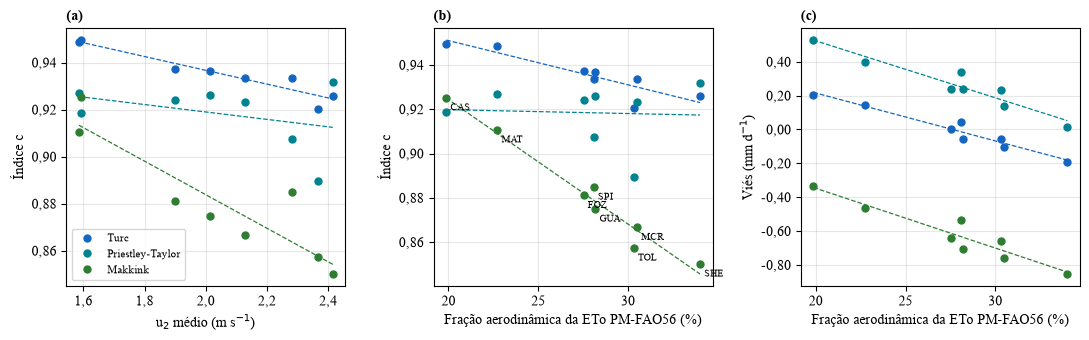

In [20]:
fig, axs = plt.subplots(1, 3, figsize=(11, 3.5))
siglas = municipios.set_index("Municipio").Sigla
paineis = [("u2", "c", "u$_2$ médio (m s$^{-1}$)", "Índice c"),
           ("frac_aero", "c", "Fração aerodinâmica da ETo PM-FAO56 (%)", "Índice c"),
           ("frac_aero", "Vies", "Fração aerodinâmica da ETo PM-FAO56 (%)", "Viés (mm d$^{-1}$)")]
for ax, (xcol, ycol, xl, yl) in zip(axs, paineis):
    x = assoc[xcol] * (100 if xcol == "frac_aero" else 1)
    for met in ["Tur", "PT", "Mak"]:
        y = assoc[f"{ycol}_{met}"]
        b1, b0 = np.polyfit(x, y, 1)
        xx = np.array([x.min(), x.max()])
        ax.plot(xx, b0 + b1 * xx, color=CORES[met], lw=0.9, ls="--")
        ax.plot(x, y, "o", color=CORES[met], ms=5, label=NOMES[met])
    ax.set_xlabel(xl); ax.set_ylabel(yl)
    ax.xaxis.set_major_formatter(fmt_eixo(1 if xcol == "u2" else 0)); ax.yaxis.set_major_formatter(fmt_eixo(2))
    ax.grid(alpha=0.3)
axs[0].legend(fontsize=8, loc="lower left")
for mun, row in assoc.iterrows():
    axs[1].annotate(siglas[mun], (row.frac_aero * 100, row.c_Mak), xytext=(3, -9), textcoords="offset points", fontsize=7)
for a, l in zip(axs, "abc"):
    a.set_title(f"({l})", loc="left", fontweight="bold")
plt.tight_layout()
plt.savefig(DIR_FIG / "fig_vento_desempenho.png")
plt.show()

## 9. Variação sazonal do erro

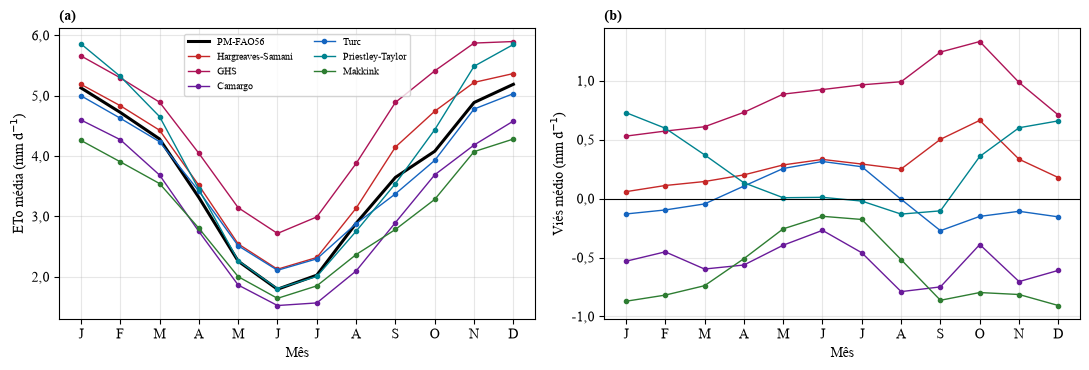

,Tur,PT,Mak,HS,GHS,Cam
Data,,,,,,
1,-0.13,0.73,-0.87,0.06,0.53,-0.53
2,-0.10,0.60,-0.82,0.11,0.57,-0.45
3,-0.05,0.37,-0.74,0.14,0.61,-0.60
4,0.11,0.13,-0.51,0.20,0.73,-0.56
5,0.26,0.01,-0.26,0.29,0.89,-0.40
6,0.31,0.01,-0.15,0.33,0.93,-0.27
7,0.27,-0.02,-0.18,0.29,0.97,-0.46
8,-0.01,-0.13,-0.52,0.25,0.99,-0.79
9,-0.27,-0.10,-0.86,0.50,1.24,-0.75


In [21]:
mens = pool.groupby(pool.index.month)[["PM"] + METODOS].mean()
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].plot(mens.index, mens.PM, "k-", lw=2.2, label="PM-FAO56")
for met in ORDEM_FIG:
    axs[0].plot(mens.index, mens[met], "-o", ms=3, color=CORES[met], lw=1, label=NOMES[met])
    axs[1].plot(mens.index, mens[met] - mens.PM, "-o", ms=3, color=CORES[met], lw=1, label=NOMES[met])
axs[1].axhline(0, color="k", lw=0.8)
axs[0].set_ylabel("ETo média (mm d$^{-1}$)"); axs[1].set_ylabel("Viés médio (mm d$^{-1}$)")
meses = ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]
for a, l in zip(axs, "ab"):
    a.set_xticks(range(1, 13), meses); a.set_xlabel("Mês"); a.grid(alpha=0.3)
    a.yaxis.set_major_formatter(fmt_eixo(1)); a.set_title(f"({l})", loc="left", fontweight="bold")
axs[0].legend(fontsize=7.5, ncol=2)
plt.tight_layout()
plt.savefig(DIR_FIG / "fig_sazonalidade.png")
plt.show()
mens.round(2).to_csv(DIR_TAB / "eto_media_mensal_regional.csv")
(mens[METODOS].sub(mens.PM, axis=0)).round(2)

## 10. Sensibilidade: PM-FAO56 com o vento nativo `WS2M`

Reproduz o procedimento do TCC (vento `WS2M` do POWER) para quantificar o efeito da escolha da variável de vento.

In [22]:
serie_ws2m = {m.Municipio: processar(m, brutos[m.Municipio], u2_col="WS2M") for _, m in municipios.iterrows()}
sens = []
for mun in independentes:
    a, b = serie[mun], serie_ws2m[mun]
    lin = {"Municipio": mun, "u2_WSC": a.u2.mean(), "u2_WS2M": b.u2.mean(),
           "ETo_WSC": a.PM.mean(), "ETo_WS2M": b.PM.mean(),
           "frac_aero_WSC": a.PM_aero.sum() / a.PM.sum(), "frac_aero_WS2M": b.PM_aero.sum() / b.PM.sum()}
    for met in ["PT", "Mak", "Tur"]:
        lin[f"c_{met}_WSC"] = metricas(a.PM, a[met])["c"]
        lin[f"c_{met}_WS2M"] = metricas(b.PM, b[met])["c"]
    sens.append(lin)
sens = pd.DataFrame(sens).set_index("Municipio")
sens.to_csv(DIR_TAB / "sensibilidade_vento_WS2M.csv", float_format="%.4f")
sens.round(3)

,u2_WSC,u2_WS2M,ETo_WSC,ETo_WS2M,frac_aero_WSC,frac_aero_WS2M,c_PT_WSC,c_PT_WS2M,c_Mak_WSC,c_Mak_WS2M,c_Tur_WSC,c_Tur_WS2M
Municipio,,,,,,,,,,,,
Cascavel,1.592,0.091,3.305,3.060,0.199,0.015,0.919,0.934,0.925,0.958,0.950,0.950
Foz do Iguaçu,1.900,0.868,3.703,3.415,0.275,0.150,0.924,0.953,0.881,0.942,0.937,0.960
Guaíra,2.013,0.616,3.816,3.426,0.282,0.109,0.926,0.949,0.875,0.953,0.937,0.963
Marechal Cândido Rondon,2.128,1.579,3.875,3.721,0.305,0.248,0.923,0.946,0.867,0.904,0.934,0.953
Matelândia,1.586,0.184,3.453,3.108,0.227,0.033,0.927,0.940,0.911,0.959,0.949,0.945
Santa Helena,2.415,2.332,3.966,3.950,0.340,0.335,0.932,0.938,0.850,0.854,0.926,0.929
São Pedro do Iguaçu,2.280,0.740,3.581,3.287,0.281,0.115,0.907,0.942,0.885,0.951,0.934,0.960
Toledo,2.366,0.989,3.745,3.435,0.303,0.156,0.890,0.939,0.857,0.937,0.920,0.959


## 11. Figuras de dispersão

Menor fração aerodinâmica: Cascavel 0.199 | maior: Santa Helena 0.34


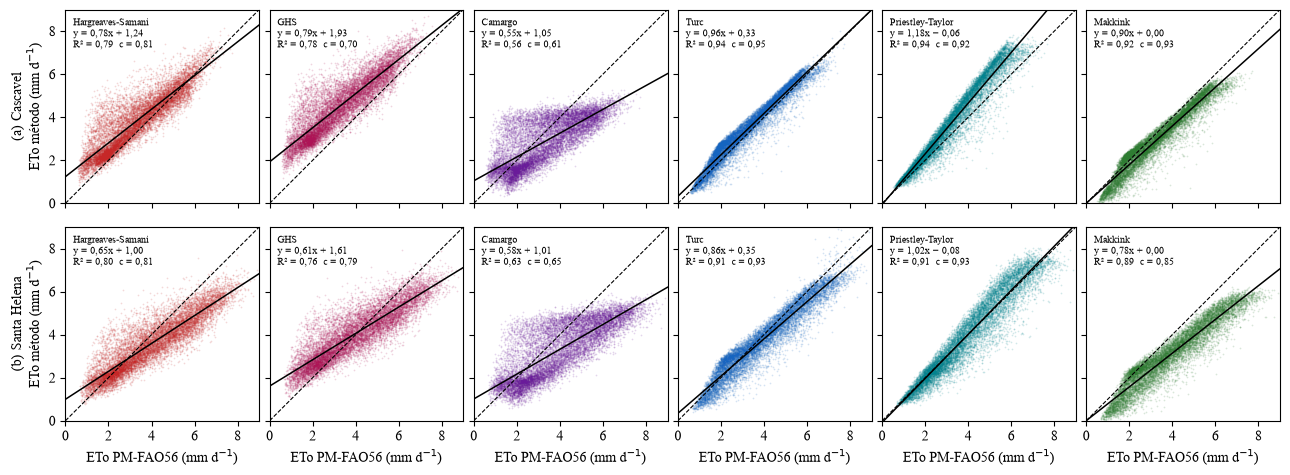

In [23]:
# Séries com a menor e a maior contribuição aerodinâmica na ETo do PM-FAO56
mun_baixo, mun_alto = assoc.frac_aero.idxmin(), assoc.frac_aero.idxmax()
print("Menor fração aerodinâmica:", mun_baixo, round(assoc.frac_aero.min(), 3),
      "| maior:", mun_alto, round(assoc.frac_aero.max(), 3))
fig_dispersao([mun_baixo, mun_alto], "fig_dispersao.png",
              rotulos=[f"(a) {mun_baixo}", f"(b) {mun_alto}"])

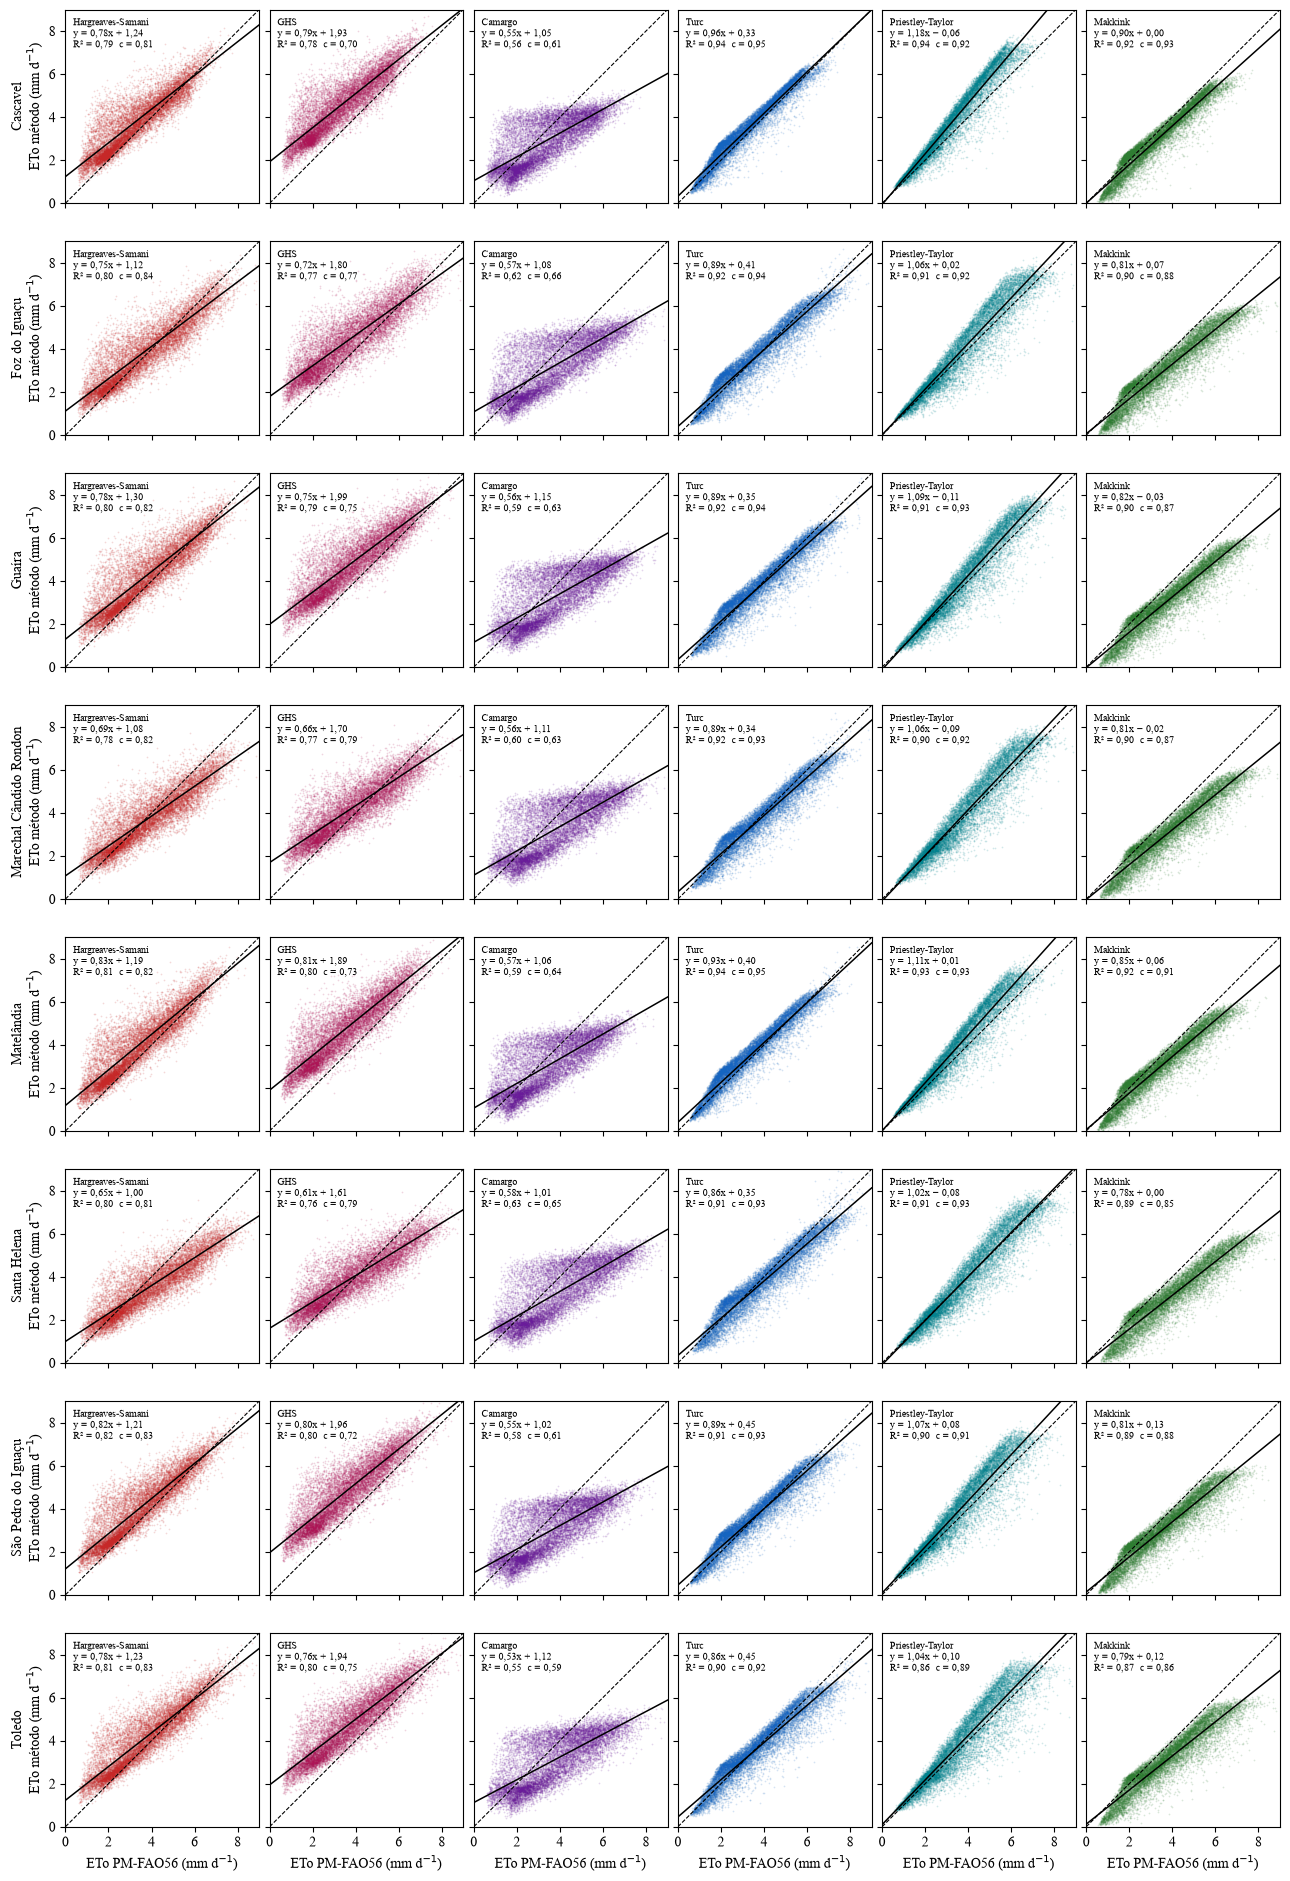

In [24]:
# Dispersões de todas as séries independentes (material suplementar)
fig_dispersao(sorted(independentes), "fig_dispersao_todos.png")

## 12. Resumo dos números citados no artigo

In [25]:
resumo = {
    "periodo": f"{df.index.min():%d/%m/%Y} a {df.index.max():%d/%m/%Y}",
    "dias_por_municipio": len(df) // len(serie),
    "series_met_independentes": len(grupos_met),
    "grupos_met": grupos_met,
    "grupos_rad": grupos_rad,
    "dias_Rs_maior_Rso_pct": float((df.Rs > df.Rso).mean() * 100),
    "Ra_astro_menos_POWER": float((df.Ra - df.Ra_POWER).mean()),
    "F_camargo": {k: v.attrs["F_camargo"] for k, v in serie.items()},
    "gradiente_Tmed_C_100m_regressao": float(np.polyfit(clima.Alt, clima.Tmed_mean, 1)[0] * 100),
    "r_Tmed_Alt": float(np.corrcoef(clima.Alt, clima.Tmed_mean)[0, 1]),
    "ETo_media_regional": float(pool.PM.mean()),
    "ETo_anual_regional": float(pool.groupby([pool.Municipio, pool.index.year]).PM.sum().mean()),
    "frac_aero_regional": float(pool.PM_aero.sum() / pool.PM.sum()),
}
(DIR_TAB / "resumo_numeros.json").write_text(json.dumps(resumo, ensure_ascii=False, indent=2), encoding="utf-8")
resumo

{'periodo': '01/01/1995 a 31/12/2025',
 'dias_por_municipio': 11323,
 'series_met_independentes': 8,
 'grupos_met': [['Cascavel'],
  ['Foz do Iguaçu', 'Medianeira', 'São Miguel do Iguaçu'],
  ['Guaíra'],
  ['Marechal Cândido Rondon'],
  ['Matelândia'],
  ['Santa Helena'],
  ['São Pedro do Iguaçu'],
  ['Toledo']],
 'grupos_rad': [['Cascavel', 'Matelândia'],
  ['Foz do Iguaçu', 'Medianeira', 'São Miguel do Iguaçu'],
  ['Guaíra', 'Marechal Cândido Rondon', 'Santa Helena'],
  ['São Pedro do Iguaçu', 'Toledo']],
 'dias_Rs_maior_Rso_pct': 0.7727634019252848,
 'Ra_astro_menos_POWER': 0.30091141643779273,
 'F_camargo': {'Cascavel': 0.01,
  'Foz do Iguaçu': 0.01,
  'Guaíra': 0.01,
  'Marechal Cândido Rondon': 0.01,
  'Matelândia': 0.01,
  'Medianeira': 0.01,
  'Santa Helena': 0.01,
  'São Miguel do Iguaçu': 0.01,
  'São Pedro do Iguaçu': 0.01,
  'Toledo': 0.01},
 'gradiente_Tmed_C_100m_regressao': -0.5831849271014732,
 'r_Tmed_Alt': -0.856296842480987,
 'ETo_media_regional': 3.680569606530077,
